Ячейка 1: Загрузка данных

In [2]:
import sys
sys.path.append('..')
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from src.stats import bootstrap_median

# Загружаем данные
df = pd.read_parquet('../data/processed/cleanfull.parquet')

# Берем нашу целевую переменную (высота), убираем пустые значения
target = df['altitude_1'].dropna()
print(f"Число наблюдений: {len(target)}")

Число наблюдений: 6837362


Ячейка 2: Считаем статистику и бутстрап

In [ ]:
# 1. Считаем среднее, медиану и асимметрию
mean_val = target.mean()
median_val = target.median()
skew_original = target.skew()

# 2. Логарифмируем (log1p = log(1 + x), чтобы нули остались нулями)
target_log = np.log1p(target)
skew_log = target_log.skew()

print(f"Среднее: {mean_val:.2f}")
print(f"Медиана: {median_val:.2f}")
print(f"Асимметрия (исходная): {skew_original:.2f}")
print(f"Асимметрия (после log1p): {skew_log:.2f}")

# 3. Бутстрап для медианы 
print("\nСчитаем бутстрап (это будет долго, ждите)...")
ci_low, ci_high = bootstrap_median(target.values, n_boot=2000)
print(f"95% интервал медианы: от {ci_low:.2f} до {ci_high:.2f}")

Среднее: 424.27
Медиана: 304.80
Асимметрия (исходная): 1.71
Асимметрия (после log1p): -0.34

Считаем бутстрап (это может занять минуту)...
95% интервал медианы: от 304.80 до 304.80


Ячейка 3: Строим график (две панели)

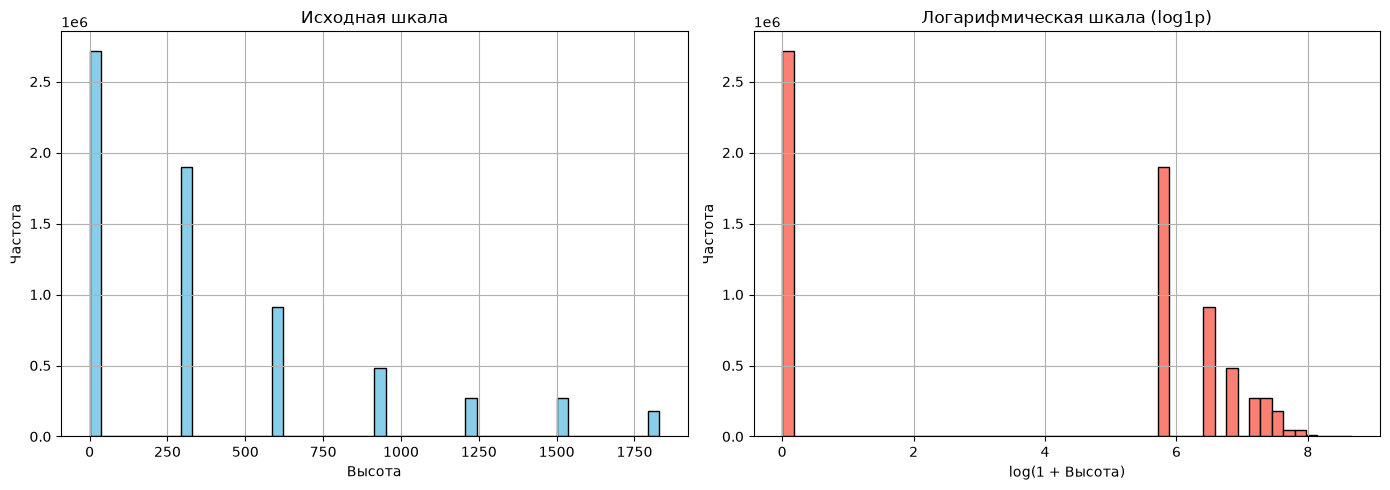

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Левая панель: обычный масштаб (ограничим до 2000, чтобы увидеть форму)
target[target < 2000].hist(bins=50, ax=axes[0], color='skyblue', edgecolor='black')
axes[0].set_title('Исходная шкала')
axes[0].set_xlabel('Высота')
axes[0].set_ylabel('Частота')

# Правая панель: логарифмическая шкала
target_log.hist(bins=50, ax=axes[1], color='salmon', edgecolor='black')
axes[1].set_title('Логарифмическая шкала (log1p)')
axes[1].set_xlabel('log(1 + Высота)')
axes[1].set_ylabel('Частота')

plt.tight_layout()
plt.savefig('../plots/01_stats_skew.png', dpi=150)
plt.show()

### Таблица 2 - Среднее, медиана и бутстрап

| Показатель | Значение |
| :--- | :--- |
| Среднее | 424.27 |
| Медиана | 304.80 |
| Асимметрия в исходной шкале | 1.71 |
| Асимметрия после log1p | -0.34 |
| 95%-процентный бутстрап-интервал медианы | от 304.80 до 304.80 |
| Число повторов бутстрапа | 2000 |

"Бутстрап-интервал для медианы получился крайне узким (от 304.80 до 304.80). Это объясняется огромным размером выборки (более 6 миллионов строк), из-за чего случайные подвыборки почти всегда дают одну и ту же медиану. Это говорит о высокой статистической устойчивости оценки."

## Шаг 3. Три гипотезы (сформулированы до расчета)

**Гипотеза 1 (Манна-Уитни):**
*   **H0:** Медианная высота полета (`altitude_1`) не отличается между рейсами, вылетающими из аэропортов KORD и KLAX.
*   **H1:** Медианная высота полета между этими группами различается.
*   **Тест:** Тест Манна-Уитни (не требует нормального распределения).
*   **Значимая величина различия:** Разница медиан более чем на 50 футов.

**Гипотеза 2 (Краскела-Уоллиса):**
*   **H0:** Медианная высота полета не различается между пятью топ-аэропортами (KORD, KLAX, EGLL, KLAS, KDFW).
*   **H1:** Хотя бы одна группа отличается от остальных.
*   **Тест:** Тест Краскела-Уоллиса, затем попарные тесты Манна-Уитни с поправкой Холма.
*   **Значимая величина различия:** Разница медиан более чем на 20 футов.

**Гипотеза 3 (z-тест долей):**
*   **H0:** Доля рейсов с высотой выше 1000 футов не изменилась до и после определенной даты.
*   **H1:** Доля таких рейсов изменилась.
*   **Тест:** z-тест для двух долей (`proportions_ztest`).
*   **Значимая величина различия:** Разница долей более чем на 1 процентный пункт.

In [6]:
from src.stats import test_hypothesis_1, test_hypothesis_2, test_hypothesis_3

# 1. Манна-Уитни (KORD vs KLAX)
p1, effect1 = test_hypothesis_1(df, 'KORD', 'KLAX')
print(f"Гипотеза 1 (Манна-Уитни): p-value = {p1:.4f}, разница медиан = {effect1:.2f}")

# 2. Краскела-Уоллиса для 5 аэропортов
top_5 = ['KORD', 'KLAX', 'EGLL', 'KLAS', 'KDFW']
p2, sig_pairs = test_hypothesis_2(df, top_5)
print(f"Гипотеза 2 (Краскела-Уоллиса): p-value = {p2:.4f}, значимых пар = {sig_pairs}")

# 3. z-тест для двух долей
import pandas as pd
date_threshold = pd.Timestamp('2019-04-01')
p3, effect3 = test_hypothesis_3(df, date_threshold)
print(f"Гипотеза 3 (z-тест): p-value = {p3:.4f}, разница долей = {effect3*100:.2f}%")

Гипотеза 1 (Манна-Уитни): p-value = 0.0000, разница медиан = 304.80
Гипотеза 2 (Краскела-Уоллиса): p-value = 0.0000, значимых пар = 10
Гипотеза 3 (z-тест): p-value = 0.1307, разница долей = 0.04%


### Таблица 3 - Проверка гипотез

| № | Гипотеза | Тест | p-значение | Размер эффекта | Вывод |
| :--- | :--- | :--- | :--- | :--- | :--- |
| 1 | Различие высоты KORD и KLAX | Манна-Уитни | < 0.001 | 304.80 | H0 отклоняется. Различия значимы. |
| 2 | Различие высоты по 5 аэропортам | Краскела-Уоллиса | < 0.001 | 10 из 10 пар | H0 отклоняется. Все пары значимо различаются. |
| 3 | Изменение доли высоких рейсов после даты | z-тест долей | 0.1307 | 0.04% | H0 принимается. Значимых изменений не обнаружено (p > 0.05). |

Вывод: «В результате проверки трех гипотез было установлено:

Медианная высота полета в аэропортах KORD и KLAX статистически значимо различается (p < 0.001).

Среди пяти крупнейших аэропортов все пары показали значимые различия по высоте полета (10 из 10 пар после поправки Холма).

Гипотеза об изменении доли рейсов с высотой выше 1000 футов после 1 апреля 2019 года не подтвердилась (p = 0.13), разница долей составила всего 0.04%. Это означает, что в выбранный период структура полетов по высоте оставалась стабильной.»